# SDE fitting on a hematopoiesis dataset

Here, we use the hematopoiesis dataset by [Paul et al. (2015)](https://doi.org/10.1016/j.cell.2015.11.013) to fit a gene regulatory SDE model using a PseudotimeDataset, with cells sampled at different pseudo time points.
We only use a small subset of genes that are the regulators of the erythroid/myeloid lineage bifurcation, a well-understood system mainly regulated by the two transcription factors Spi1 and Gata1.

We adjust the loss to put more weight on the later time points and add a sparsity penalty (L1) for the adjacency matrix.

We use the model trained with optimized hyperparameters (including regularization strength), where the early-stopping patience was set to 100 epochs instead of the default 5. Train/validation/test splitting was done based on time points.

In [1]:
import random
from pathlib import Path

import networkx as nx
import numpy as np
import optuna
import pandas as pd
import scanpy as sc
import seaborn as sns
import torch
from bowside.dataset import PseudotimeDataset
from bowside.model import GRNModelSDE
from bowside.sensitivity import simulate_all_knockouts
from bowside.training import integrate_model, sinkhorn_loss
from bowside.trajectory import infer_cell_fates, infer_trajectories
from matplotlib import pyplot as plt
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend

In [2]:
# Make output directory
OUT_DIR = Path("../output/hematopoiesis")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Load data
name = "weighted_sinkhorn_time_point_split"
adata = sc.read_h5ad("../data/hematopoiesis_processed.h5ad")
display(adata)
adj_list = pd.read_csv("../data/grns/tflink_mm.csv")
display(adj_list)
study = optuna.load_study(
    study_name=f"hematopoiesis_Paul_MAGIC_tuning_{name}",
    storage=JournalStorage(
        JournalFileBackend(f"../output/tuning/hematopoiesis/{name}/journal.log")
    ),
)

AnnData object with n_obs × n_vars = 2317 × 1999
    obs: 'paul15_clusters', 'n_counts_all', 'n_counts', 'louvain', 'cell_type', 'louvain_annot', 'dpt_pseudotime', 'palantir_pseudotime', 'palantir_entropy'
    var: 'n_counts', 'hematopoiesis_gene'
    uns: 'DM_EigenValues', 'cell_type_colors', 'diffmap_evals', 'draw_graph', 'iroot', 'log1p', 'louvain', 'louvain_annot_colors', 'louvain_colors', 'louvain_sizes', 'neighbors', 'paga', 'palantir_waypoints', 'paul15_clusters_colors', 'pca'
    obsm: 'DM_EigenVectors', 'DM_EigenVectors_multiscaled', 'X_diffmap', 'X_draw_graph_fa', 'X_pca', 'branch_masks', 'palantir_fate_probabilities'
    varm: 'PCs', 'gene_trends_Erythroids', 'gene_trends_Granulocytes', 'gene_trends_Monocytes'
    obsp: 'DM_Kernel', 'DM_Similarity', 'connectivities', 'distances'
    layers: 'MAGIC_imputed_data', 'imputed', 'imputed_log1p', 'log1p', 'raw_count', 'scaled', None

,source,target,small_scale
0,Rfx5,H2-Ab1,Yes
1,Rela,Trim63,Yes
2,Creb1,Chgb,Yes
3,Mybl1,Rfx2,Yes
4,Hif1a,Bax,Yes
...,...,...,...
4057577,Smyd3,Slc38a10,No
4057578,Stag2,Rtp4,No
4057579,Sirt6,Ppp1r3e,No
4057580,Nr4a1,Mrpl49,No


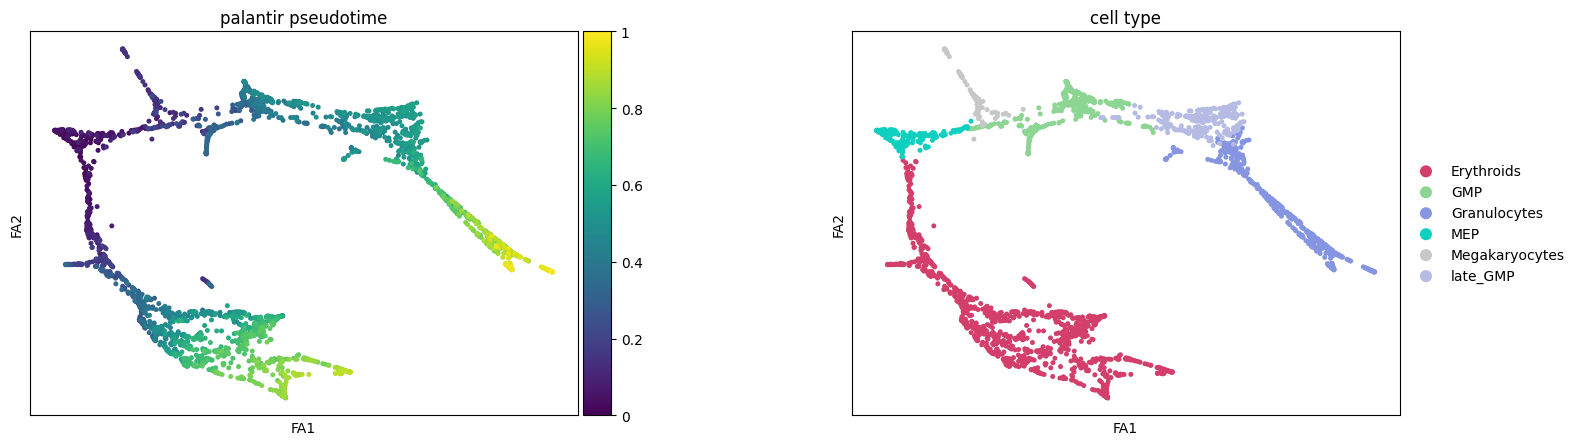

In [4]:
# Look at the data
sc.pl.scatter(adata, color=["palantir_pseudotime", "cell_type"], basis="draw_graph_fa")

In [5]:
# Use only hematopoiesis genes
layer = "MAGIC_imputed_data"
dataset = PseudotimeDataset(
    adata,
    layer=layer,
    mask_var="hematopoiesis_gene",
    pseudotime_key="palantir_pseudotime",
)

In [6]:
# Make input GRN
grn = nx.from_pandas_edgelist(
    adj_list[
        (adj_list["source"].isin(dataset.gene_names))
        & (adj_list["target"].isin(dataset.gene_names))
        & (adj_list["small_scale"] == "Yes")
    ],
    source="source",
    target="target",
    create_using=nx.DiGraph,
)
for gene in dataset.gene_names:
    if gene not in grn.nodes():
        grn.add_node(gene)

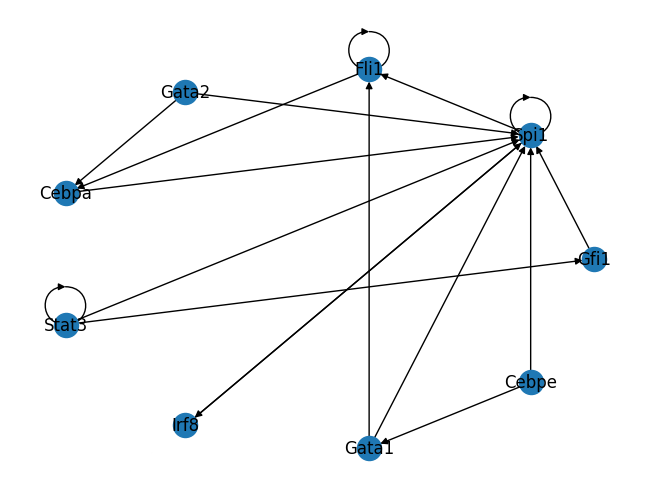

In [7]:
nx.draw_circular(grn, with_labels=True)

In [8]:
study.best_params

{'adj_init_normal': 'False',
 'sigma': 0.3001353914649445,
 'shared_sigma': 'False',
 'fixed_sigma': 'False',
 'constant_noise': 'False',
 'optimizer': 'Adam',
 'lr': 0.06179204192775724,
 'num_epochs': 4000,
 'solver_method': 'euler',
 'regularization_strength': 3.360513760954196e-05}

In [9]:
trials_df = study.trials_dataframe().sort_values(by="value")
trials_df

,number,value,datetime_start,datetime_complete,duration,params_adj_init_normal,params_constant_noise,params_fixed_sigma,params_lr,params_num_epochs,params_optimizer,params_regularization_strength,params_shared_sigma,params_sigma,params_solver_method,state
190,190,0.072289,2026-07-16 17:40:07.794356,2026-07-16 17:41:26.029631,0 days 00:01:18.235275,False,False,False,0.061792,4000.0,Adam,0.000034,False,0.300135,euler,COMPLETE
49,49,0.073000,2026-07-16 16:22:02.338668,2026-07-16 16:23:27.760286,0 days 00:01:25.421618,False,False,False,0.088284,1000.0,Adam,0.000034,False,0.153313,milstein,COMPLETE
53,53,0.076484,2026-07-16 16:23:27.775232,2026-07-16 16:25:01.815221,0 days 00:01:34.039989,False,False,False,0.099902,1500.0,Adam,0.000064,False,0.211020,milstein,COMPLETE
63,63,0.078077,2026-07-16 16:27:36.240635,2026-07-16 16:28:37.786801,0 days 00:01:01.546166,False,False,False,0.098215,1000.0,Adam,0.000038,False,0.107290,milstein,COMPLETE
177,177,0.082076,2026-07-16 17:28:50.784830,2026-07-16 17:30:31.048573,0 days 00:01:40.263743,False,False,False,0.063376,1500.0,Adam,0.000046,False,0.619140,milstein,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,90,NaN,2026-07-16 16:43:00.445694,2026-07-16 16:43:01.854040,0 days 00:00:01.408346,False,False,True,NaN,NaN,NaN,NaN,False,0.171785,NaN,PRUNED
110,110,NaN,2026-07-16 16:55:06.702910,2026-07-16 16:55:08.064388,0 days 00:00:01.361478,False,False,True,NaN,NaN,NaN,NaN,False,0.257591,NaN,PRUNED
130,130,NaN,2026-07-16 17:04:22.077585,2026-07-16 17:04:23.660005,0 days 00:00:01.582420,False,False,True,NaN,NaN,NaN,NaN,False,1.304931,NaN,PRUNED
131,131,NaN,2026-07-16 17:04:22.138298,2026-07-16 17:04:23.650942,0 days 00:00:01.512644,False,False,True,NaN,NaN,NaN,NaN,False,1.433281,NaN,PRUNED


In [10]:
# Setup
rank = 1  # get <rank>-best model
params = trials_df.iloc[rank - 1].to_dict()
sigma = params["params_sigma"]
adj_init_normal = params["params_adj_init_normal"] == "True"
shared_sigma = params["params_shared_sigma"] == "True"
fixed_sigma = params["params_fixed_sigma"] == "True"
constant_noise = params["params_constant_noise"] == "True"

model = GRNModelSDE(
    dataset.n_genes(),
    adj=None,
    adj_init_normal=adj_init_normal,
    activation="sigmoid",
    sigma=sigma,
    shared_sigma=shared_sigma,
    fixed_sigma=fixed_sigma,
    constant_noise=constant_noise,
)

In [11]:
# Load model
trial_number = params["number"]
checkpoint_dir = f"../output/tuning/hematopoiesis/{name}/{trial_number}/"
checkpoint = torch.load(
    f"{checkpoint_dir}/checkpoint_final_model.tar",
    weights_only=True,
    map_location=torch.device("cpu"),
)
model.load_state_dict(checkpoint["model_state_dict"])
train_losses = np.load(f"{checkpoint_dir}/train_losses.npy")
test_losses = np.load(f"{checkpoint_dir}/test_losses.npy")

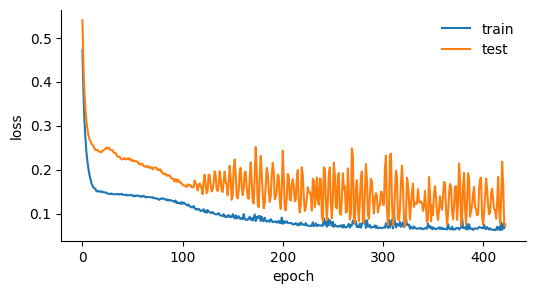

In [12]:
fig, ax = plt.subplots(figsize=(6, 3))

ax.plot(train_losses, label="train")
ax.plot(test_losses, label="test")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend(loc="upper right", frameon=False)
sns.despine(fig);

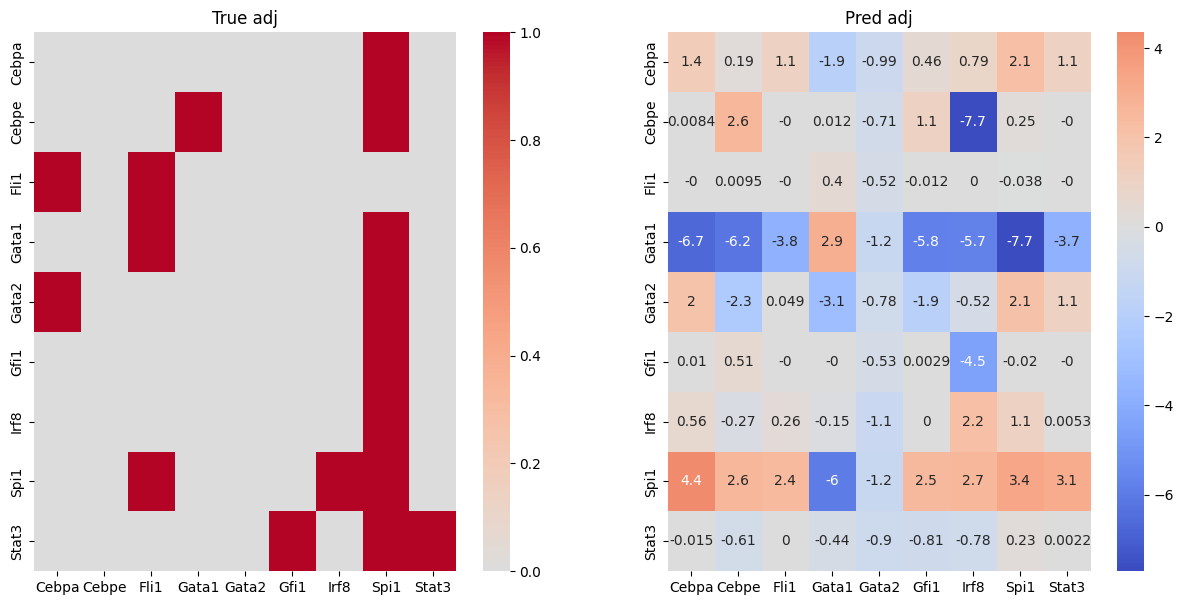

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))

sns.heatmap(
    nx.to_pandas_adjacency(grn, weight="effect", nodelist=dataset.gene_names),
    annot=False,
    cmap="coolwarm",
    center=0,
    ax=axs[0],
)
axs[0].set_title("True adj")
sns.heatmap(
    pd.DataFrame(
        model.adj.detach(),
        index=dataset.gene_names,
        columns=dataset.gene_names,
    ),
    annot=True,
    cmap="coolwarm",
    center=0,
    ax=axs[1],
)
axs[1].set_title("Pred adj");

In [14]:
y = dataset[:]
y0 = y[:, 0, :]
ts = dataset.time_points
dt = 0.01

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
pred = integrate_model(
    model, y0, time_points=ts, solver_method=params["params_solver_method"]
)

In [15]:
alpha = 10.0 / len(dataset)

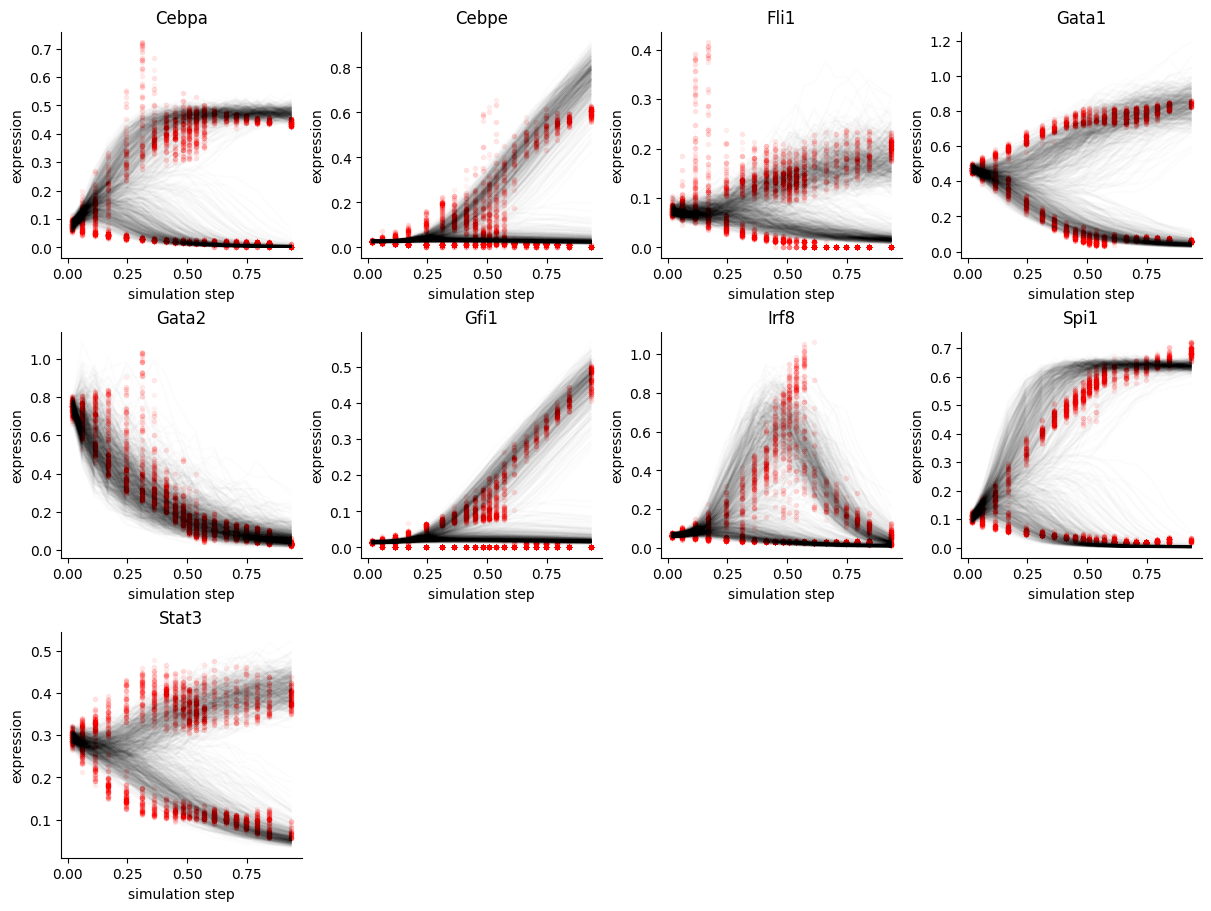

In [16]:
n_rows = dataset.n_genes() // 4 + 1
n_cols = 4
fig, axs = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3), layout="constrained"
)

for i, ax in enumerate(axs.flat):
    if i < len(dataset.gene_names):
        gene_name = dataset.gene_names[i]
        ax.scatter(
            ts.cpu().repeat((dataset[:].shape[0], 1)),
            y[:, :, i].detach().cpu(),
            color="r",
            linewidth=0,
            s=15,
            alpha=alpha,  # label="true"
        )
        ax.plot(
            ts.cpu(),
            pred[:, :, i].detach().cpu(),
            color="k",
            alpha=alpha,  # label="pred"
        )
        ax.set_xlabel("simulation step")
        ax.set_ylabel("expression")
        ax.set_title(gene_name)
    else:
        ax.set_axis_off()

sns.despine(fig);

In [17]:
# Perform trajectory inference with the fitted model
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
infer_trajectories(
    dataset, model, dt=0.01, solver_method=params["params_solver_method"]
)
infer_cell_fates(dataset)

# Perform KO simulations
_, _ = simulate_all_knockouts(
    dataset, model, sinkhorn_loss, dt=0.01, solver_method=params["params_solver_method"]
)

In [19]:
# Save adjacency matrix
adj_mat = pd.DataFrame(
    model.adj.detach().numpy(),
    index=dataset.gene_names,
    columns=dataset.gene_names,
)
adj_mat.to_csv(OUT_DIR / "hematopoiesis_adj_bowside.csv")
adj_list[
    (adj_list["source"].isin(dataset.gene_names))
    & (adj_list["target"].isin(dataset.gene_names))
].to_csv(OUT_DIR / "hematopoiesis_adj_list_tflink.csv", index=False)

In [20]:
# Save AnnData object
adata.write_h5ad("../data/hematopoiesis_bowside.h5ad", compression="gzip")

In [21]:
# Subset data and simulations for overview figure
gene_mask = dataset.gene_names.isin(["Cebpe", "Gata1", "Spi1"])
data_subset = dataset[:].detach().numpy()[::10, ::4, gene_mask]
simulations_subset = adata.uns["bowside"]["simulations"][::4, ::10, gene_mask]
trajectory_labels_subset = adata.uns["bowside"]["trajectory_inference_clusters"][::10]
trajectories_subset = adata.uns["bowside"]["trajectories"][:, ::4, gene_mask]
np.savez(
    OUT_DIR / "bowside_results_overview.npz",
    data=data_subset,
    simulations=simulations_subset,
    trajectory_labels=trajectory_labels_subset,
    trajectories=trajectories_subset,
)